## Digits Classification

Load dependencies and the Digits dataset, check for errorneous values, and plot the class sizes, pixel intensity distribution, and the distribution of the amount of ink in each image. The data is then split 70/30 into a training set and a test set.

0 missing or out-of-range values detected


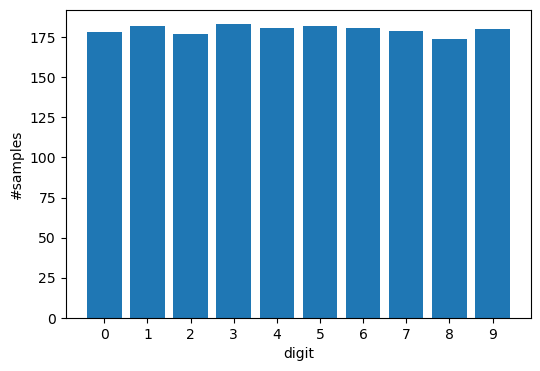

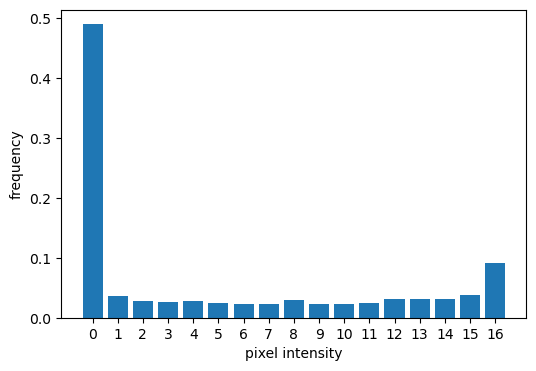

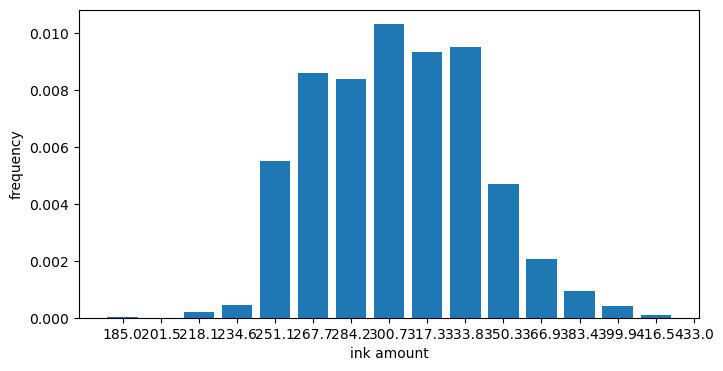

In [1]:
import os
import pprint
import sys
import time
import numpy as np
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
    sys.path.insert(0, "src")

from MLP import MLP
from MulticlassSVM import MulticlassSVM
from helpers import *

digits = load_digits()
X, y = digits.data, digits.target

# Check for missing or out-of-range values
cnt = 0
for (i, j) in zip(*np.nonzero(np.isnan(X))):
    r, c = divmod(j, 8)
    print(f"Missing value: #{i} ({r},{c})")
    cnt += 1
for (i, j) in zip(*np.nonzero(np.logical_or(X < 0, X > 16))):
    r, c = divmod(j, 8)
    print(f"{X[i, j]} is out of range: #{i} ({r},{c})")
    cnt += 1
print(f"{cnt} missing or out-of-range values detected")

# Plot class sizes
counts = np.bincount(y, minlength=10)
fig, ax = plt.subplots(figsize=(6, 4))
xs = np.arange(10)
ax.bar(xs, counts)
ax.set_xlabel("digit")
ax.set_ylabel("#samples")
ax.set_xticks(xs)

# Plot pixel intensity distribution
dist, _ = np.histogram(X.reshape(-1), bins=np.arange(-0.5, 17.5, 1.0), density=True)
fig, ax = plt.subplots(figsize=(6, 4))
xs = np.arange(0, 17)
ax.bar(xs, dist)
ax.set_xlabel("pixel intensity")
ax.set_ylabel("frequency")
ax.set_xticks(xs)

# Plot ink amount distribution
dist, bins = np.histogram(np.sum(X, axis=1), bins=15, density=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(bins[:-1], dist, width=(bins[1]-bins[0])*4/5)
ax.set_xlabel("ink amount")
ax.set_ylabel("frequency")
ax.set_xticks(bins)

plt.show()
plt.close()

# 70/30 train/test split with seed 42. Stratification proves helpful
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.7, random_state=42, stratify=y)

### Multiclass SVM

Use grid search to find the best lambda and learning rate with a fixed number of iterations. Variate each of these parameters with the other fixed to the best values and plot the cross-validation accuracy.

Best validation accuracy: 0.9480
Best hyperparameters: {'lambda_param': 0.0001, 'learning_rate': 0.01, 'n_iters': 400}


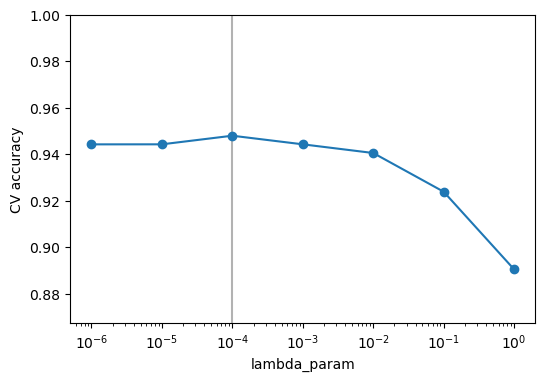

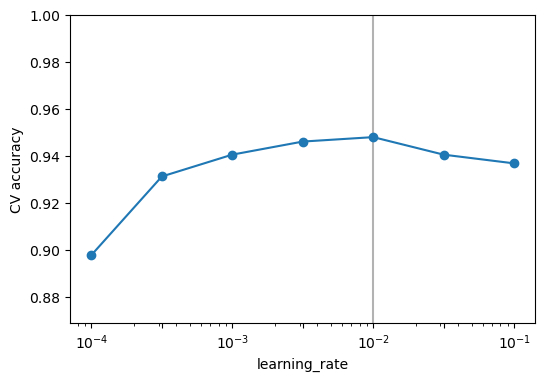

In [5]:
svm_grid = {
    "lambda_param": np.logspace(-6, 0, 7).tolist(),
    "learning_rate": np.logspace(-4, -1, 7).tolist(),
    "n_iters": 400
}
svm_plot_config = {
    "lambda_param": ("log", "accuracy"),
    "learning_rate": ("log", "accuracy")
}
build_svm = lambda p: MulticlassSVM(**p)
grid, best_idx = grid_search(build_svm, svm_grid, X_train, y_train)
svm_best_params = grid.index_to_params(best_idx)
print(f"Best validation accuracy: {grid[best_idx]["test_score"]:.4f}")
print("Best hyperparameters:", svm_best_params)
plot_slices(grid, best_idx, svm_plot_config)

Variate the number of iterations and plot the cross-validation accuracy and the mean training time during cross-validation.

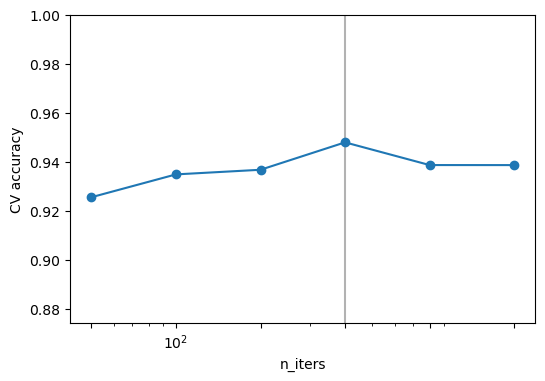

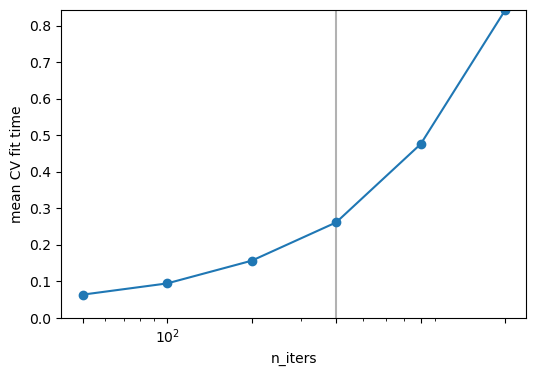

In [8]:
params = svm_best_params.copy()
params["n_iters"] = [50, 100, 200, 400, 800, 1600]
grid, best_idx = grid_search(build_svm, params, X_train, y_train)
params = grid.index_to_params(best_idx)
plot_slices(grid, best_idx, {"n_iters": ("log", "both")})

Train the model on the entire training set and test with the test set. Report prediction time and accuracy.

In [13]:
svm = build_svm(svm_best_params).fit(X_train, y_train)
start = time.perf_counter()
y_pred = svm.predict(X_test)
pred_time = time.perf_counter() - start
print(f"Prediction time on test set: {pred_time*1000:.4f} ms")
print(f"Accuracy on test set: {accuracy(y_pred, y_test):.4f}")

Prediction time on test set: 0.5418 ms
Accuracy on test set: 0.9483


### 2-layer MLP

Use grid search to find the best hidden layer size and learning rate with a fixed epochs. Variate each of these parameters with the other fixed to the best values and plot the cross-validation accuracy. The mean training time during cross-validation vs. the hidden layer size is also plotted.

Best validation accuracy: 0.9647
Best hyperparameters: {'epochs': 400, 'hidden_size': 96, 'learning_rate': 0.06812920690579612}


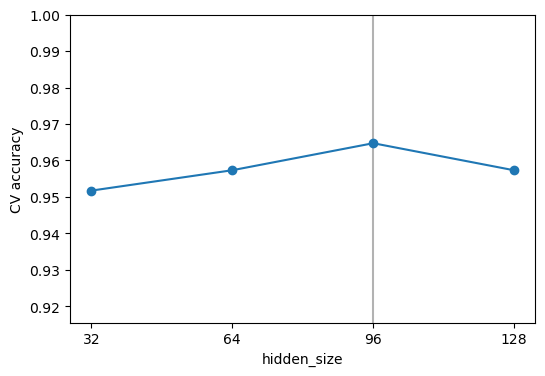

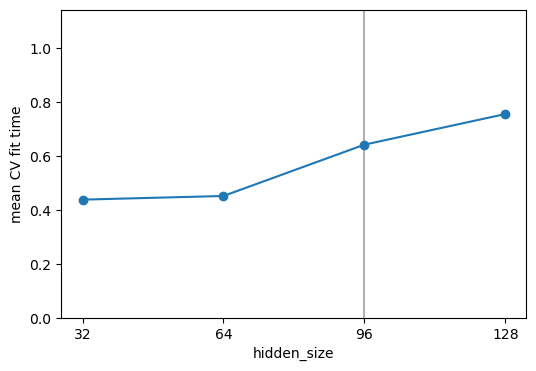

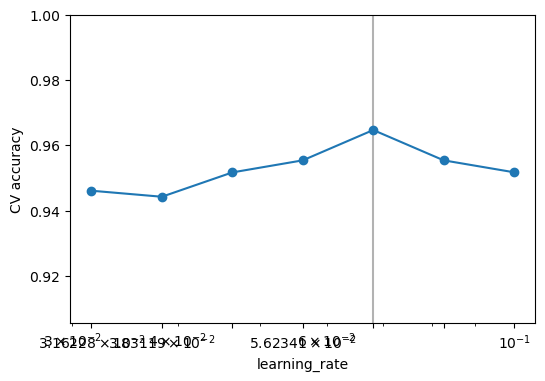

In [17]:
mlp_grid = {
    "hidden_size": [32, 64, 96, 128],
    "learning_rate": np.logspace(-1.5, -1, 7).tolist(),
    "epochs": 400
}
mlp_plot_config = {
    "hidden_size": ("linear", "both"),
    "learning_rate": ("log", "accuracy")
}
build_mlp = lambda p: MLP2(input_size=X.shape[1], output_size=10, **p)
grid, best_idx = grid_search(build_mlp, mlp_grid, X_train, y_train)
mlp_best_params = grid.index_to_params(best_idx)
print(f"Best validation accuracy: {grid[best_idx]["test_score"]:.4f}")
print("Best hyperparameters:", mlp_best_params)
plot_slices(grid, best_idx, mlp_plot_config)

Variate the epochs and plot the cross-validation accuracy and the mean training time during cross-validation.

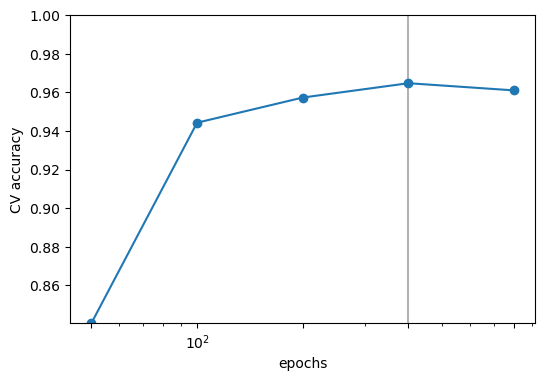

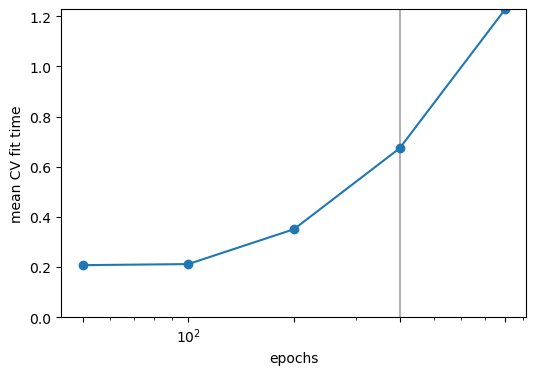

In [18]:
params = mlp_best_params.copy()
params["epochs"] = [50, 100, 200, 400, 800]
grid, best_idx = grid_search(build_mlp, params, X_train, y_train)
params = grid.index_to_params(best_idx)
plot_slices(grid, best_idx, {"epochs": ("log", "both")})

Train the model on the entire training set and test with the test set. Report prediction time and accuracy.

In [21]:
mlp = build_mlp(mlp_best_params).fit(X_train, y_train)
start = time.perf_counter()
y_pred = mlp.predict(X_test)
pred_time = time.perf_counter() - start
print(f"Prediction time on test set: {pred_time*1000:.4f} ms")
print(f"Accuracy on test set: {accuracy(y_pred, y_test):.4f}")

Prediction time on test set: 3.3967 ms
Accuracy on test set: 0.9666


### Random Forest Classifier

Use grid search to find the best number of estimators and the best maximum depth. Variate each of these parameters with the other fixed to the best values and plot the cross-validation accuracy.

Best validation accuracy: 0.9592
Best hyperparameters: {'max_depth': 15, 'n_estimators': 128}


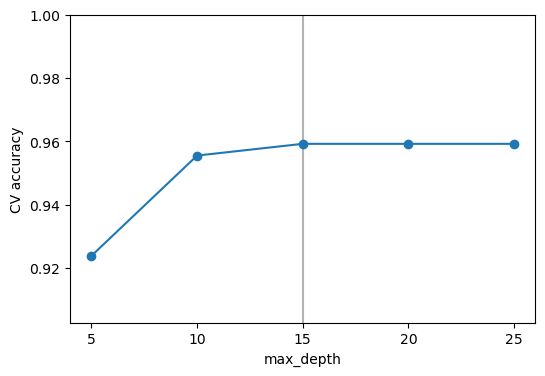

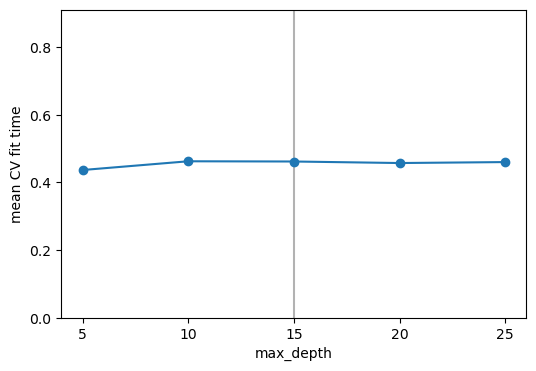

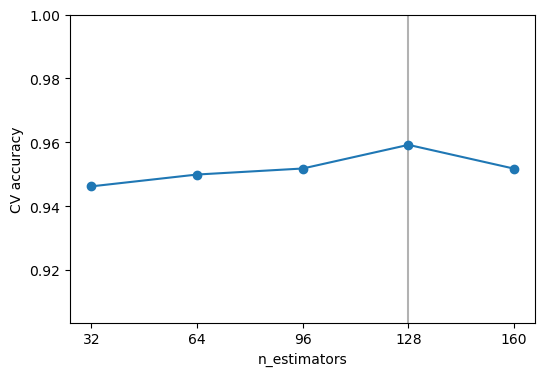

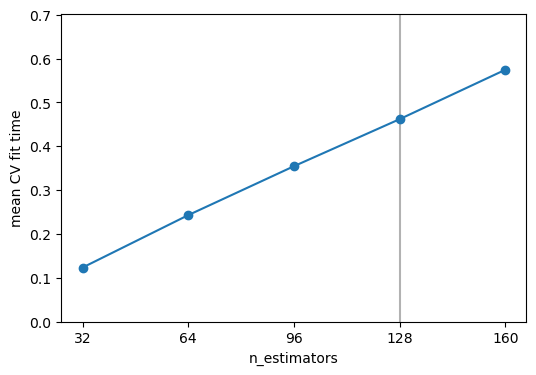

In [22]:
rf_grid = {
    "n_estimators": [32, 64, 96, 128, 160],
    "max_depth": [5, 10, 15, 20, 25]
}
rf_plot_config = {
    "n_estimators": ("linear", "both"),
    "max_depth": ("linear", "both")
}
build_rf = lambda p: RandomForestClassifier(random_state=42, **p)
grid, best_idx = grid_search(build_rf, rf_grid, X_train, y_train)
rf_best_params = grid.index_to_params(best_idx)
print(f"Best validation accuracy: {grid[best_idx]["test_score"]:.4f}")
print("Best hyperparameters:", rf_best_params)
plot_slices(grid, best_idx, rf_plot_config)

Train the model on the entire training set and test with the test set. Report prediction time and accuracy.

In [26]:
rf = build_rf(rf_best_params).fit(X_train, y_train)
start = time.perf_counter()
y_pred = rf.predict(X_test)
pred_time = time.perf_counter() - start
print(f"Prediction time on test set: {pred_time*1000:.4f} ms")
print(f"Accuracy on test set: {accuracy(y_pred, y_test):.4f}")

Prediction time on test set: 39.4098 ms
Accuracy on test set: 0.9571
